# 01 — EDA : Consommation électrique (London Smart Meters, version agrégée)
Fichier utilisé : `elec_block.csv` (dataset Kaggle *Smart meters in London — processed*).

**Format** : format *large* — une colonne `tstp` (horodatage demi-horaire) et 112 colonnes `block_0 … block_111`.
Chaque valeur = consommation (kWh par demi-heure) **moyenne par foyer** d'un bloc (~50 foyers). Les cases vides = bloc pas encore actif.

Objectifs : vérifier le format, agréger **par heure**, (optionnel) joindre météo et jours fériés, et sauvegarder `data/processed/consumption_hourly.csv` (entrée du notebook 03).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

RAW_DIR  = "../data/raw/london_smart_meters"
ELEC_CSV = f"{RAW_DIR}/elec_block.csv"
WEATHER_CSV = f"{RAW_DIR}/weather_hourly_darksky.csv"   # optionnel (voir section 6)
OUT_PATH = "../data/processed/consumption_hourly.csv"
FIG_DIR  = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Chargement

In [2]:
df = pd.read_csv(ELEC_CSV, parse_dates=["tstp"], index_col="tstp").sort_index()
df = df.astype("float32")
print(df.shape, "| période :", df.index.min(), "->", df.index.max())
print("Pas de temps :", df.index.to_series().diff().mode()[0])
df.iloc[:5, :6]

(39727, 112) | période : 2011-11-23 09:00:00 -> 2014-02-28 00:00:00
Pas de temps : 0 days 00:30:00


,block_0,block_1,block_10,block_100,block_101,block_102
tstp,,,,,,
2011-11-23 09:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2011-11-23 09:30:00,NaN,NaN,NaN,NaN,NaN,NaN
2011-11-23 10:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2011-11-23 10:30:00,NaN,NaN,NaN,NaN,NaN,NaN
2011-11-23 11:00:00,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Vérification du format
Si les valeurs sont des **moyennes par foyer**, on attend ~0.05 à 1 kWh par demi-heure. Si c'étaient des **sommes** de ~50 foyers, on verrait plutôt 5 à 30 kWh.

In [3]:
vals = df.stack()
print(vals.describe().round(3))
print("Valeurs négatives :", (vals < 0).sum())
print("Doublons d'index :", df.index.duplicated().sum())

count    4312953.000
mean           0.217
std            0.123
min            0.000
25%            0.136
50%            0.192
75%            0.267
max            4.462
dtype: float64
Valeurs négatives : 0
Doublons d'index : 0


## 3. Couverture : combien de blocs sont actifs au cours du temps ?

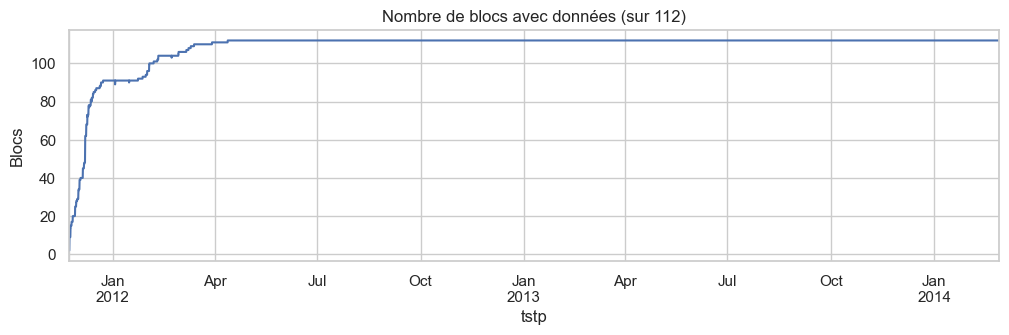

Période stable : 2011-12-21 14:30:00 -> 2014-02-28 00:00:00 | 38371 lignes


In [4]:
n_active = df.notna().sum(axis=1)
n_active.plot(figsize=(12, 3), title="Nombre de blocs avec données (sur 112)")
plt.ylabel("Blocs"); plt.savefig(f"{FIG_DIR}/conso_blocs_actifs.png", dpi=150); plt.show()

# On garde la période où au moins 80 % des blocs sont actifs (série stable)
thr = 0.8 * df.shape[1]
stable = df[n_active >= thr]
print("Période stable :", stable.index.min(), "->", stable.index.max(), "|", len(stable), "lignes")

## 4. Agrégation : blocs → ville, demi-heure → heure
- Moyenne des 112 blocs (≈ moyenne par foyer ; les blocs ont une taille proche, ~50 foyers).
- Heure = somme des 2 demi-heures (kWh par foyer et par heure). On rejette les heures où il manque une demi-heure.

In [5]:
hh = pd.DataFrame({"mean": stable.mean(axis=1), "std_blocks": stable.std(axis=1)})
grp = hh["mean"].resample("h")
hourly = pd.DataFrame({
    "mean_kwh": grp.sum(min_count=2),             # NaN si une demi-heure manque
    "std_blocks": hh["std_blocks"].resample("h").mean(),
})
print("Heures manquantes :", hourly["mean_kwh"].isna().sum(), "sur", len(hourly))
hourly["mean_kwh"] = hourly["mean_kwh"].interpolate(limit=3)
hourly["std_blocks"] = hourly["std_blocks"].interpolate(limit=3)
hourly = hourly.dropna()
hourly.index.name = "timestamp"
hourly.describe().round(3)

Heures manquantes : 3 sur 19187


,mean_kwh,std_blocks
count,19186.000,19186.000
mean,0.434,0.081
std,0.152,0.049
min,0.185,0.021
25%,0.324,0.051
50%,0.419,0.068
75%,0.519,0.092
max,0.954,0.439


## 5. Visualisations de la consommation

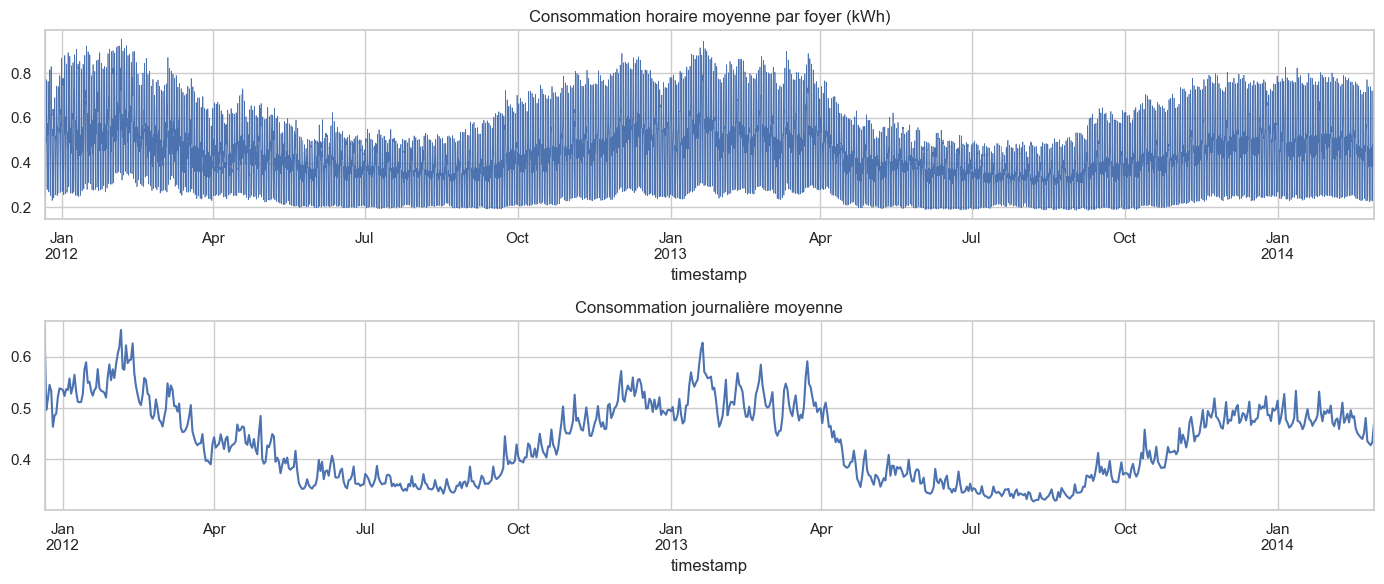

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6))
hourly["mean_kwh"].plot(ax=ax[0], lw=0.5)
ax[0].set_title("Consommation horaire moyenne par foyer (kWh)")
hourly["mean_kwh"].resample("D").mean().plot(ax=ax[1])
ax[1].set_title("Consommation journalière moyenne")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/conso_timeseries.png", dpi=150); plt.show()

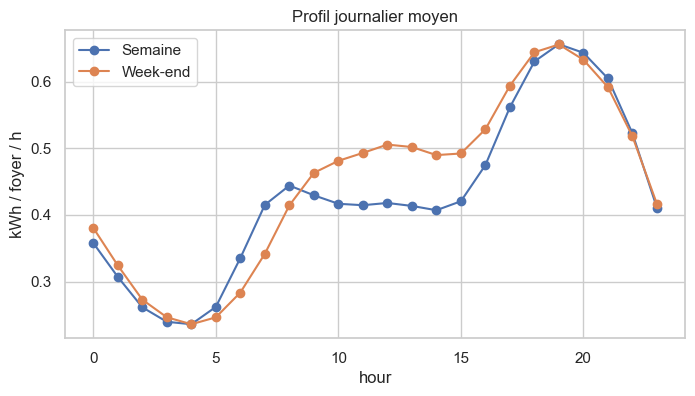

In [7]:
hourly["hour"] = hourly.index.hour
hourly["dow"] = hourly.index.dayofweek
hourly["is_weekend"] = (hourly["dow"] >= 5).astype(int)

prof = hourly.groupby(["is_weekend", "hour"])["mean_kwh"].mean().unstack(0)
prof.columns = ["Semaine", "Week-end"]
prof.plot(figsize=(8, 4), marker="o", title="Profil journalier moyen")
plt.ylabel("kWh / foyer / h"); plt.savefig(f"{FIG_DIR}/conso_profil_jour.png", dpi=150); plt.show()

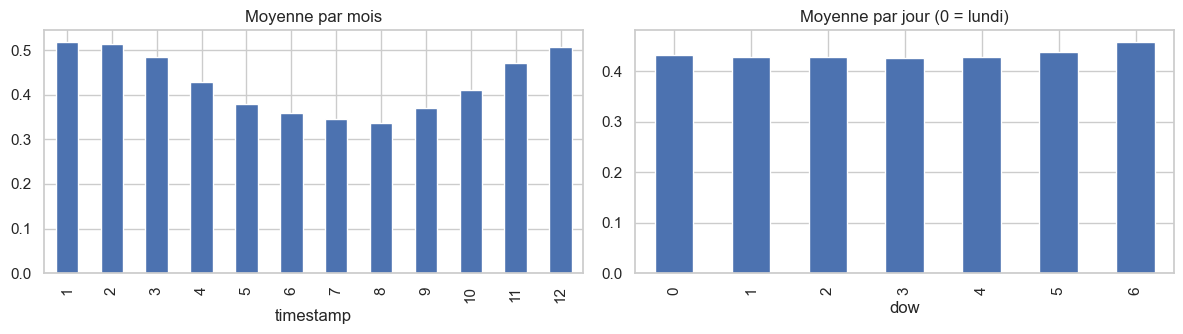

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
hourly.groupby(hourly.index.month)["mean_kwh"].mean().plot(kind="bar", ax=ax[0], title="Moyenne par mois")
hourly.groupby("dow")["mean_kwh"].mean().plot(kind="bar", ax=ax[1], title="Moyenne par jour (0 = lundi)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/conso_saison.png", dpi=150); plt.show()

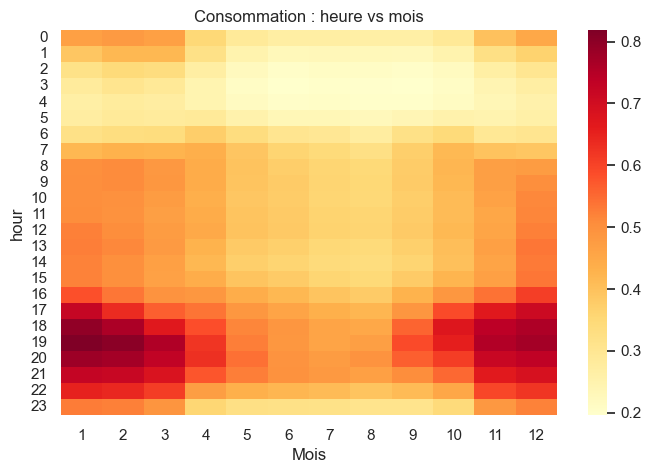

In [9]:
pivot = hourly.pivot_table(index="hour", columns=hourly.index.month, values="mean_kwh")
plt.figure(figsize=(8, 5))
sns.heatmap(pivot, cmap="YlOrRd")
plt.title("Consommation : heure vs mois"); plt.xlabel("Mois"); plt.show()

{1: np.float64(0.935), 2: np.float64(0.78), 3: np.float64(0.581), 6: np.float64(0.028), 12: np.float64(-0.043), 24: np.float64(0.967), 48: np.float64(0.943), 168: np.float64(0.964)}


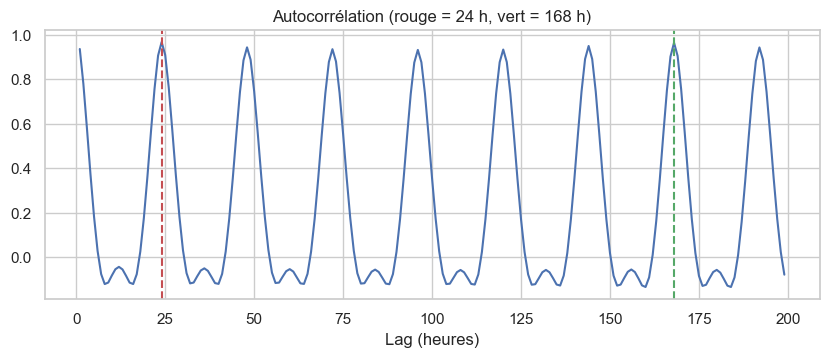

In [10]:
# Autocorrélation : la consommation dépend du passé (24 h, 168 h)
s = hourly["mean_kwh"]
print({l: round(s.autocorr(l), 3) for l in [1, 2, 3, 6, 12, 24, 48, 168]})
plt.figure(figsize=(10, 3.5))
plt.plot(range(1, 200), [s.autocorr(l) for l in range(1, 200)])
plt.axvline(24, color="r", ls="--"); plt.axvline(168, color="g", ls="--")
plt.title("Autocorrélation (rouge = 24 h, vert = 168 h)"); plt.xlabel("Lag (heures)")
plt.savefig(f"{FIG_DIR}/conso_autocorr.png", dpi=150); plt.show()

## 6. Hétérogénéité entre blocs

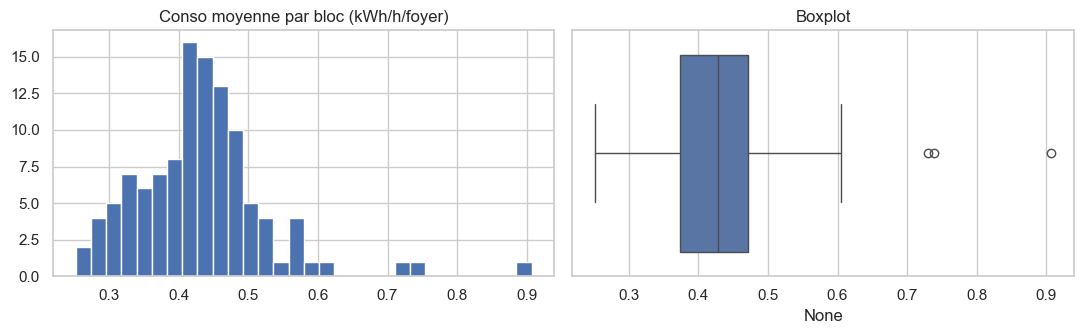

count    112.000
mean       0.432
std        0.096
min        0.252
25%        0.374
50%        0.428
75%        0.472
max        0.907
dtype: float64

In [11]:
block_mean = stable.mean() * 2    # kWh/h moyen par foyer pour chaque bloc
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
block_mean.hist(bins=30, ax=ax[0]); ax[0].set_title("Conso moyenne par bloc (kWh/h/foyer)")
sns.boxplot(x=block_mean, ax=ax[1]); ax[1].set_title("Boxplot")
plt.tight_layout(); plt.show()
block_mean.describe().round(3)

## 7. Jours fériés et météo (optionnels)
- **Jours fériés** : calculés avec le package `holidays` (`pip install holidays`), sans fichier supplémentaire.
- **Météo** : nécessite `weather_hourly_darksky.csv` du dataset Kaggle original (petit fichier, téléchargeable seul). S'il est absent, on continue sans météo.

In [12]:
data = hourly.copy()

# Jours fériés (Royaume-Uni)
try:
    import holidays
    uk = holidays.UK(years=sorted(set(data.index.year)))
    data["is_holiday"] = [int(d in uk) for d in data.index.date]
    print("Jours fériés détectés :", data["is_holiday"].sum() // 24, "jours")
except ImportError:
    data["is_holiday"] = 0
    print("Package 'holidays' absent -> is_holiday = 0  (pip install holidays)")

# Météo
weather_cols = []
if os.path.exists(WEATHER_CSV):
    w = pd.read_csv(WEATHER_CSV, parse_dates=["time"]).set_index("time").sort_index()
    w = w[~w.index.duplicated()]
    weather_cols = [c for c in ["temperature", "humidity", "windSpeed", "pressure", "cloudCover"] if c in w.columns]
    data = data.join(w[weather_cols], how="left")
    data[weather_cols] = data[weather_cols].interpolate(limit=6)
    data = data.dropna(subset=weather_cols)
    print("Météo jointe :", weather_cols)
else:
    print("Pas de fichier météo -> modèle avec calendrier + lags seulement")
data.head()

Jours fériés détectés : 18 jours
Météo jointe : ['temperature', 'humidity', 'windSpeed', 'pressure']


,mean_kwh,std_blocks,hour,dow,is_weekend,is_holiday,temperature,humidity,windSpeed,pressure
timestamp,,,,,,,,,,
2011-12-21 15:00:00,0.535041,0.209954,15,2,0,0,12.14,0.93,4.02,1018.25
2011-12-21 16:00:00,0.574089,0.205394,16,2,0,0,12.07,0.92,4.12,1018.90
2011-12-21 17:00:00,0.692239,0.243978,17,2,0,0,12.02,0.90,4.73,1019.66
2011-12-21 18:00:00,0.759327,0.285018,18,2,0,0,11.97,0.89,4.47,1020.03
2011-12-21 19:00:00,0.758298,0.286146,19,2,0,0,11.93,0.89,3.61,1020.65


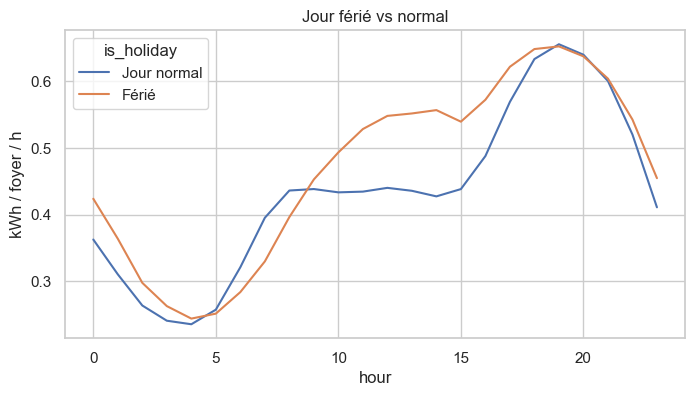

In [13]:
# Effet des jours fériés
if data["is_holiday"].sum() > 0:
    data.groupby(["is_holiday", "hour"])["mean_kwh"].mean().unstack(0).rename(
        columns={0: "Jour normal", 1: "Férié"}).plot(figsize=(8, 4), title="Jour férié vs normal")
    plt.ylabel("kWh / foyer / h"); plt.show()

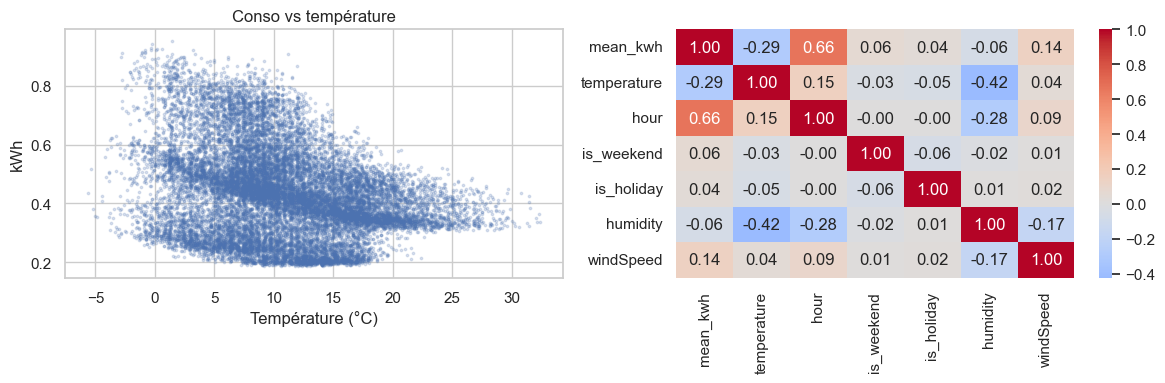

In [14]:
# Effet de la température (si la météo est disponible)
if "temperature" in data.columns:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].scatter(data["temperature"], data["mean_kwh"], s=3, alpha=0.2)
    ax[0].set_xlabel("Température (°C)"); ax[0].set_ylabel("kWh"); ax[0].set_title("Conso vs température")
    cols = ["mean_kwh", "temperature", "hour", "is_weekend", "is_holiday"] + [c for c in ["humidity", "windSpeed"] if c in data.columns]
    sns.heatmap(data[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1])
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/conso_meteo.png", dpi=150); plt.show()

## 8. Valeurs aberrantes

In [15]:
z = (data["mean_kwh"] - data["mean_kwh"].mean()) / data["mean_kwh"].std()
print("Points avec |z| > 4 :", (z.abs() > 4).sum())
data.loc[z.abs() > 4, ["mean_kwh"]].head(10)

Points avec |z| > 4 : 0


,mean_kwh
timestamp,


## 9. Sauvegarde des données traitées

In [16]:
keep = ["mean_kwh", "std_blocks", "is_holiday"] + weather_cols
final = data[keep].copy()
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
final.to_csv(OUT_PATH)
print("Sauvegardé :", OUT_PATH, final.shape)
final.head()

Sauvegardé : ../data/processed/consumption_hourly.csv (19186, 7)


,mean_kwh,std_blocks,is_holiday,temperature,humidity,windSpeed,pressure
timestamp,,,,,,,
2011-12-21 15:00:00,0.535041,0.209954,0,12.14,0.93,4.02,1018.25
2011-12-21 16:00:00,0.574089,0.205394,0,12.07,0.92,4.12,1018.90
2011-12-21 17:00:00,0.692239,0.243978,0,12.02,0.90,4.73,1019.66
2011-12-21 18:00:00,0.759327,0.285018,0,11.97,0.89,4.47,1020.03
2011-12-21 19:00:00,0.758298,0.286146,0,11.93,0.89,3.61,1020.65


## Conclusions
- Période retenue : 21/12/2011 → 28/02/2014, quand au moins 80 % des 112 blocs ont des données. Après passage à l'heure : **19 186 heures** (3 heures manquantes comblées par interpolation).
- Consommation moyenne : **0,43 kWh par foyer et par heure**, entre 0,19 et 0,95. Aucune valeur négative, aucun point avec |z| > 4.
- Profil journalier : minimum vers 4 h (0,24 kWh), plateau de 8 h à 15 h (≈ 0,44 kWh), **pic le soir vers 19 h (0,66 kWh)**. Consommation plus élevée en hiver et un peu plus le week-end (0,448 contre 0,428 kWh).
- Autocorrélation très forte à 1 h (0,94), 24 h (0,97) et 168 h (0,96) → les retards (lags) seront les variables les plus utiles.
- Météo (température, humidité, vent, pression) et jours fériés (18 jours) ajoutés. La température est corrélée négativement à la consommation (r = −0,29).
- Sortie : `data/processed/consumption_hourly.csv`, utilisé par le notebook 03.